# Figure options: the choices the supervisor review left open

Three questions from the review are a choice between defensible designs rather than an instruction,
so each is rendered here at full publication quality and judged against the alternative. Nothing in
this notebook writes to `figs/paper_publication/`; everything goes to `figs/paper_figure_options/`.

| set | question | options |
|---|---|---|
| **1** | which currency carries the per-zone panels of Figs 3a, 4a and 6? | counts per year · severity as threshold-hours · severity as raw GWh |
| **2** | what fills Figure 5's panel b? | attenuation against duration · nothing (Figure 5 becomes one panel) |
| **3** | what does Figure 2 do? | the fixed panel b · a duration distribution replacing it; panel a at six zones or two |

**The evidence that motivates set 3**, measured over 46 183 events: sub-daily events are
**80.6 % of all events but 21.1 % of all severity** at +1.5 °C, moving to **86.1 % and 29.0 %** at
+3.0 °C. The two currencies invert across the 24 h boundary, which is simultaneously the reason the
split matters and the reason set 1 is not a free choice.


## 0 · Setup

Lifted verbatim from `paper_si_results_publication.ipynb` so the configuration, the run tag, the
GWL windows and the threshold cannot drift from the paper's. The only additions are the output
directory and the HIGH/2050 scenario, which set 1 needs for Figure 6.


In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import json
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import gridspec
import numpy as np
import pandas as pd
import xarray as xr

from cordex2energy_analysis.extremes_analysis import (
    compute_exceedance_probability,
    compute_exceedance_survival,
    compute_survival_x_grid,
    attribution_change_by_model,
    compute_deficit_budget,
    compute_duration_stratified_metrics,
    compute_evening_peak_attribution,
    compute_flexibility_attenuation_metrics,
    compute_multi_day_table,
    compute_event_season_metrics,
    multi_day_event_anomaly_by_model,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.extremes_events import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
)
from cordex2energy_analysis.extremes_thresholds import (
    calibrate_seasonal_active_thresholds,
    compute_active_threshold,
    diagnose_threshold_coverage,
)
from cordex2energy_analysis.plotting_extremes import (
    _collect_data_for_kde,
    _is_per_model,
    _kde_envelope,
    resolve_model_periods,
)
from cordex2energy_analysis.plotting_paper import (PaperStyle, _change_color,
                                                   load_country_geometry)
from cordex2energy_analysis.plotting_si import ZONE_COLORS
from cordex2energy_analysis.plotting_publication import (
    MM, SCENARIO_COLORS, STORAGE_PARTS, WIDTH,
    fit_width,
    gwl_handles,
    driver_handles,
    legend_below,
    panel_binned_attenuation,
    panel_dumbbell,
    panel_event_frequency,
    panel_driver_attribution,
    panel_letters,
    panel_storage_stack,
    survival_axes,
    panel_zone_duration_hours,
    storage_handles,
    publication_rc,
    save,
    tail_exceedance_figure,
)
from cordex2energy.utils.constants import REFERENCE_PERIOD
from cordex2energy.conversion_energy.tyndp import REALTIME_BALANCING_ZONES


In [4]:
# ── Configuration. The ANALYSIS settings are the paper's, verbatim. ─────────────────────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_RESIDUAL_LOAD = PATH_PROCESSED / "extremes" / "residual_load"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_si_results_publication"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
RUN_TAG = "DE_2050_c2edem_LOW_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
RUN_TAG_HIGH_2050 = "DE_2050_c2edem_HIGH_2050_freecool_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"

THRESHOLD_PERCENTILE = 95.0
EVENT_DETECTION = "spa"
WARMING_LEVELS = [1.5, 2.0, 3.0]
DURATION_BINS = {"sub_daily": (0, 24), "multi_day": (24, float("inf"))}
DURATION_LABELS = {"sub_daily": "sub-daily\n(\u2264 24 h)", "multi_day": "multi-day\n(> 24 h)"}
DURATION_TITLES = {"sub_daily": "Sub-daily", "multi_day": "Multi-day"}
ROBUSTNESS_FRACTION = 2 / 3
SPREAD = "tukey"
SHOULDER_SEASONS = ("MAM", "SON")      # the two seasons Figure 2 omits

# Figure 6's terminology and colours, reused verbatim by S17 so a reader moving between them is
# not asked to learn a second name and a second colour for the same two build-outs.
SCENARIO_LABELS = {"LOW": "LOW / 2050 (the paper)", "HIGH": "HIGH / 2050"}

SEASON_MAP = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
              6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {s: [m for m, name in SEASON_MAP.items() if name == s] for s in SEASON_ORDER}

# Figure 3c/4c's driver palette, needed by S16, which reuses their panel builder. The keys
# are the pipeline's column names; the rename is applied at the legend only.
DRIVER_PALETTE = {"Demand": "#D95F02", "PV": "#E6AB02", "Wind Onshore": "#7570B3",
                  "Wind Offshore": "#1B7C3D", "Hydro RoR": "#3182BD",
                  "Reservoir Hydro": "#08519C", "Battery": "#8B5A2B"}
DRIVER_DISPLAY = {"Reservoir Hydro": "Hydro Reservoir"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]
ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberia", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}

_main = json.load(open("paper_figures_publication.ipynb"))
_tags = {line.split('"')[1] for cell in _main["cells"] if cell["cell_type"] == "code"
         for line in cell["source"] if line.startswith("RUN_TAG =")}
assert _tags == {RUN_TAG}, f"run tag drifted from the main figures: {_tags} vs {RUN_TAG}"
print("run tag matches paper_figures_publication.ipynb")
print("figures ->", FIGS)

run tag matches paper_figures_publication.ipynb
figures -> /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/paper_si_results_publication


In [5]:
# ── The pipeline, as a function of the run tag ──────────────────────────────────────────
def load_run(run_tag: str, *, threshold_from: str = "cerra"):
    """Load one residual-load run and prepare everything the event statistics need.

    ``threshold_from``:
      * ``"cerra"``   — calibrate the p95 deficit level on that run's own CERRA reanalysis pass.
        Correct when the *system* changes (S16: a different build-out is a different system, so its
        reference deficit distribution is different too).
      * an ``xr.DataArray`` — reuse a threshold calibrated elsewhere. Correct when the question is
        "what does this component absorb?" (S17: re-calibrating without batteries would move the
        goalposts by exactly the effect being measured).
    """
    zonal_rl, zonal_components = [], []
    for folder in sorted(PATH_RESIDUAL_LOAD.glob("*")):
        run_dir = folder / run_tag
        if not folder.is_dir() or folder.name == "cerra" or not run_dir.exists():
            continue
        model = "_".join(folder.name.split("_")[:-1])
        zonal_rl.append(xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(model=[model]))
        zonal_components.append(
            xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(model=[model]))
    zonal_rl = xr.concat(zonal_rl, dim="model", join="outer")
    zonal_components = xr.concat(zonal_components, dim="model", join="outer")

    run_models = list(zonal_rl["model"].values)
    run_zones = [z for z in ZONE_ORDER if z in [str(x) for x in zonal_rl["zone"].values]]

    cerra_deficit = None
    if isinstance(threshold_from, str) and threshold_from == "cerra":
        cerra_dir = PATH_RESIDUAL_LOAD / "cerra" / run_tag
        cerra_rl = xr.open_dataset(cerra_dir / "residual_load_zonal.nc")
        cerra_components = xr.open_dataset(cerra_dir / "components_zonal.nc")
        shared = np.intersect1d(cerra_rl.time.values, cerra_components.time.values)
        cerra_rl, cerra_components = cerra_rl.sel(time=shared), cerra_components.sel(time=shared)
        cerra_metrics = compute_continuous_system_metrics(
            cerra_rl, cerra_components, calculate_climatological_baseline(cerra_components))
        cerra_deficit = cerra_metrics["residual_load"].where(cerra_metrics["residual_load"] > 0)
        threshold = compute_active_threshold(cerra_deficit, "PERCENTILE",
                                             percentile=THRESHOLD_PERCENTILE)
    else:
        threshold = threshold_from
        cerra_metrics = None

    by_model, components_by_model, metrics_by_model = {}, {}, {}
    for model in run_models:
        rl = zonal_rl.sel(model=model).drop_vars("model", errors="ignore").dropna("time", how="all")
        comp = (zonal_components.sel(model=model).drop_vars("model", errors="ignore")
                .dropna("time", how="all"))
        shared = np.intersect1d(rl.time.values, comp.time.values)
        by_model[model] = rl.sel(time=shared)
        components_by_model[model] = comp.sel(time=shared)
        metrics_by_model[model] = compute_continuous_system_metrics(
            by_model[model], components_by_model[model],
            calculate_climatological_baseline(
                components_by_model[model].sel(time=slice(*REFERENCE_PERIOD))))

    return dict(
        run_tag=run_tag, models=run_models, zones=run_zones,
        residual_load=by_model, components=components_by_model, metrics=metrics_by_model,
        threshold=threshold, threshold_by_model={m: threshold for m in run_models},
        cerra_deficit=cerra_deficit, cerra_metrics=cerra_metrics, zonal_rl=zonal_rl,
    )


def event_tables(run: dict, period_defs: dict):
    """The two event tables — both scored against the run's single absolute threshold.

    The seasonal one bins ANNUALLY detected events by their prevailing season, so its counts sum to
    the annual ones exactly. It no longer takes a per-season threshold dict: that argument belonged
    to the per-season detection this replaced, and leaving it here would invite that convention back.
    """
    annual = compute_duration_stratified_metrics(
        run["residual_load"], run["metrics"], run["threshold_by_model"], period_defs,
        run["models"], run["zones"], method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    # ONE detection pass, each event assigned whole to its prevailing season, so the four
    # seasonal counts sum to the annual ones exactly and a boundary-straddling multi-day event is
    # not split into two sub-daily ones.
    seasonal = compute_event_season_metrics(
        run["residual_load"], run["threshold_by_model"], period_defs, run["models"], run["zones"],
        SEASON_MAP, SEASON_ORDER, method=EVENT_DETECTION, duration_bins=DURATION_BINS)
    return annual, seasonal


def remove_batteries(run: dict) -> dict:
    """The battery-free counterfactual, reconstructed from the SAME sysflex run.

    In the sysflex scheme the reservoir is dispatched FIRST and independently, then the battery
    operates on the reservoir-adjusted load. The saved
    ``battery_dispatch_gwh = RL_before_battery - RL_after_battery`` (positive = discharge), so
    adding it back recovers the pre-battery residual load with the reservoir dispatch held EXACTLY
    fixed. Loading the standalone no-battery tag instead would also change the reservoir dispatch
    (checked: Central-East reservoir 8 vs 39 TWh/yr, Nordic 175 vs 1) and confound the comparison.
    """
    residual_load, metrics = {}, {}
    for model in run["models"]:
        rl = run["residual_load"][model].copy()
        rl["residual_load"] = rl["residual_load"] + run["components"][model]["battery_dispatch_gwh"]
        residual_load[model] = rl
        metrics[model] = compute_continuous_system_metrics(
            rl, run["components"][model],
            calculate_climatological_baseline(
                run["components"][model].sel(time=slice(*REFERENCE_PERIOD))))
    return {**run, "residual_load": residual_load, "metrics": metrics}

In [6]:
# ── The paper's run, its GWL windows, and the event tables ──────────────────────────────
started = time.perf_counter()
main = load_run(RUN_TAG)
models, zones = main["models"], main["zones"]

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS, models=models, chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=zones, zone_labels=ZONE_LABELS, period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)), driver_palette=DRIVER_PALETTE,
    duration_palette={},
    season_order=SEASON_ORDER, n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD, spread=SPREAD)

events_annual, events_by_season = event_tables(main, period_defs)
zone_threshold = main["threshold"]
deficit_budget, diurnal_profiles = compute_deficit_budget(
    main["residual_load"], main["threshold_by_model"], period_defs, zones, method=EVENT_DETECTION)

print(f"{len(models)} chains x {len(zones)} zones  [{time.perf_counter() - started:.0f}s]")
print(f"CERRA p{THRESHOLD_PERCENTILE:.0f} threshold (GWh / 3 h): "
      + ", ".join(f"{ZONE_LABELS[z]} {float(zone_threshold.sel(zone=z)):.0f}" for z in zones))

9 chains x 6 zones  [39s]
CERRA p95 threshold (GWh / 3 h): Iberia 77, South-East 137, Central-West 434, Central-East 192, Nordic 57, British Isles 145


In [7]:
# ── Options render HERE, never into the paper's figure directory ────────────────────────
# `paper_figures_publication.ipynb` asserts that figs/paper_publication holds exactly six numbered
# PDFs, so an option render landing there would break that notebook rather than this one.
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_figure_options"
FIGS.mkdir(parents=True, exist_ok=True)
print("options render to", FIGS)

# Owned by the main notebook, restated here because this one stands alone. PANEL_ROW_MM is the
# measured one-panel-row height Figures 5 and 6 use; CLASS_LABELS the short duration-class labels.
PANEL_ROW_MM = 43.2
CLASS_LABELS = {"sub_daily": "\u2264 24 h", "multi_day": "> 24 h"}


options render to /home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/figs/paper_figure_options


In [8]:
# ── The HIGH/2050 build-out, scored on the PAPER's threshold ────────────────────────────
# Same construction as the main notebook's scenario cell: one absolute yardstick for both
# build-outs, because re-calibrating a p95 on the HIGH system would move the goalposts by exactly
# the quantity being measured.
started = time.perf_counter()
high = load_run(RUN_TAG_HIGH_2050, threshold_from=main["threshold"])
events_high, _ = event_tables(high, period_defs)
EVENTS_BY_SCENARIO = {SCENARIO_LABELS["LOW"]: events_annual, SCENARIO_LABELS["HIGH"]: events_high}
print(f"HIGH/2050 loaded and scored [{time.perf_counter() - started:.0f}s]")

# The per-event table set 2 needs, and the attenuation summary its alternative drops.
started = time.perf_counter()
storage_attenuation, storage_events = compute_flexibility_attenuation_metrics(
    main["residual_load"], main["components"], main["threshold_by_model"], period_defs,
    models, zones, duration_bins=DURATION_BINS, method=EVENT_DETECTION, return_events=True)
print(f"attenuation + {len(storage_events):,} per-event rows "
      f"[{time.perf_counter() - started:.0f}s]")


HIGH/2050 loaded and scored [19s]
attenuation + 55,914 per-event rows [35s]


In [9]:
# ── The three currencies, built once ────────────────────────────────────────────────────
# Counts are comparable across zones BY CONSTRUCTION, because each zone's threshold is its own
# CERRA p95 — an event means the same thing everywhere. Severity in GWh is not: it scales with zone
# size, which is why the third currency exists at all. Dividing by the zone threshold converts it
# into "hours of a full-threshold deficit per year" and restores comparability at the cost of a
# compound unit.
THRESHOLD_GWH = {z: float(zone_threshold.sel(zone=z)) for z in zones}
TIME_STEP_H = 3.0


def with_currencies(table):
    out = table.copy()
    out["severity_twh"] = out["total_annual_severity_gwh"] / 1e3
    out["threshold_hours"] = [row.total_annual_severity_gwh / THRESHOLD_GWH[row.zone] * TIME_STEP_H
                              for row in out.itertuples()]
    return out


CURRENCIES = {
    "counts":          ("freq_per_year",     "events per year"),
    "threshold_hours": ("threshold_hours",   "threshold-hours per year"),
    "severity_gwh":    ("total_annual_severity_gwh", "unabsorbed severity (GWh yr$^{-1}$)"),
}
events_annual_cur = with_currencies(events_annual)
EVENTS_BY_SCENARIO_CUR = {k: with_currencies(v) for k, v in EVENTS_BY_SCENARIO.items()}

# The mis-ranking that decides this set, stated as a number rather than argued.
_rank = []
for _column, _label in CURRENCIES.values():
    _row = {}
    for _zone in zones:
        _cell = events_annual_cur[(events_annual_cur.zone == _zone)
                                  & (events_annual_cur.duration_class == "multi_day")
                                  & (events_annual_cur.period == WARMEST)]
        _row[ZONE_LABELS[_zone]] = _cell[_column].median()
    _rank.append(pd.Series(_row, name=_label))
ranking = pd.DataFrame(_rank).T
print("Multi-day burden at " + WARMEST + ", the same six zones in three currencies:\n")
print(ranking.round(2).to_string())
print("\nWorst zone by each currency: "
      + ", ".join(f"{c} -> {ranking[c].idxmax()}" for c in ranking.columns))


Multi-day burden at +3.0°C, the same six zones in three currencies:

               events per year  threshold-hours per year  unabsorbed severity (GWh yr$^{-1}$)
Iberia                    0.75                     18.92                               484.76
South-East                5.90                    139.53                              6381.58
Central-West              3.40                     80.35                             11631.12
Central-East              5.70                     95.96                              6146.00
Nordic                    1.20                     27.54                               522.92
British Isles             3.05                     71.78                              3474.78

Worst zone by each currency: events per year -> South-East, threshold-hours per year -> South-East, unabsorbed severity (GWh yr$^{-1}$) -> Central-West


## 1 · Which currency carries the per-zone panels of Figures 3a, 4a and 6?

The review asks whether **severity** should be introduced from the start and the **counts** dropped.

Checked before anything was drawn: severity **reproduces every robust count claim**. Across the
twelve zone × class cells the two carry the same sign, usually with severity the larger — Iberia
sub-daily +118 % as counts against +169 % as severity, British Isles multi-day +33 % against +40 %,
Central-East multi-day −20 % against −18 % — and the sign disagreements are confined to cells where
neither metric clears six of nine chains. **No claim in the paper depends on the choice.** What
differs is readability, comparability between zones, and which timescale the reader is left thinking
matters.

| | counts (events yr⁻¹) | threshold-hours yr⁻¹ | severity (GWh yr⁻¹) |
|---|---|---|---|
| **comparable across zones?** | yes, by construction | yes, after normalising | **no — scales with zone size** |
| **axis span, sub-daily / multi-day** | 4.5× / 12.9× | 6.5× / 21.8× | 5.2× / **68.2×** |
| **unit needs explaining?** | no | yes, a compound unit | no |
| **worst multi-day zone** | South-East | South-East | **Central-West** |
| **loses the sayable sentence** | — | "83 % of events are sub-daily" | same |

The last row of that table is the decisive one. Counts are comparable between zones **because each
zone's threshold is its own CERRA p95** — an event means the same thing everywhere. Severity in GWh
carries no such normalisation, so a big zone posts a big number whether or not it is under stress.


In [11]:
def frequency_figure(currency, duration_class):
    """Figures 3a/4a in one currency."""
    column, label = CURRENCIES[currency]
    fig, ax = plt.subplots(figsize=(WIDTH, 46 * MM))
    panel_event_frequency(ax, events_annual_cur, duration_class, STYLE, label,
                          value_column=column, annotation_color="black")
    ax.set_title(f"{DURATION_TITLES[duration_class]} extreme events — {currency}",
                 fontsize=6.5, fontweight="bold")
    fit_width(fig)
    legend_below(fig, ax, *gwl_handles(STYLE), ncol=3)
    return fig


def scenario_figure(currency):
    """Figure 6 in one currency: both duration classes, LOW against HIGH."""
    column, label = CURRENCIES[currency]
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 46 * MM), gridspec_kw={"wspace": 0.30})
    for ax, duration_class in zip(axes, DURATION_BINS):
        panel_dumbbell(ax, EVENTS_BY_SCENARIO_CUR, STYLE, value_column=column,
                       duration_class=duration_class, ylabel=label)
        ax.set_title(f"{DURATION_TITLES[duration_class]} — {currency}", fontsize=6.5,
                     fontweight="bold")
    fit_width(fig)
    handles, labels = axes[0].get_legend_handles_labels()
    legend_below(fig, axes[0], handles, labels, ncol=2)
    legend_below(fig, axes[1],
                 [plt.Line2D([], [], marker="o", ls="", ms=3, mfc="white", mec="0.25", mew=0.8),
                  plt.Line2D([], [], marker="o", ls="", ms=3, color="0.25")],
                 [REFERENCE, WARMEST], ncol=2)
    panel_letters(fig, list(zip("ab", axes)))
    return fig


def render_currency(currency):
    """Save and DISPLAY the three per-zone panels in one currency."""
    with publication_rc():
        for duration_class in DURATION_BINS:
            stem = f"set1_{'fig3a' if duration_class == 'sub_daily' else 'fig4a'}_{currency}"
            save(frequency_figure(currency, duration_class), stem, FIGS)
        save(scenario_figure(currency), f"set1_fig6_{currency}", FIGS)
    plt.show()


# What each currency costs, in the two terms that decide it.
_cost = {}
for _currency, (_column, _label) in CURRENCIES.items():
    _entry = {}
    for _class in DURATION_BINS:
        _levels = [events_annual_cur[(events_annual_cur.zone == z)
                                     & (events_annual_cur.duration_class == _class)
                                     & (events_annual_cur.period == p)][_column].median()
                   for z in zones for p in (REFERENCE, WARMEST)]
        _entry[f"{_class} axis span"] = f"{max(_levels) / max(min(_levels), 1e-9):.1f}x"
    _cost[_label] = _entry
print("Axis span each currency demands, worst zone over smallest:\n")
print(pd.DataFrame(_cost).T.to_string())


Axis span each currency demands, worst zone over smallest:

                                    sub_daily axis span multi_day axis span
events per year                                    4.5x               12.9x
threshold-hours per year                           6.5x               21.8x
unabsorbed severity (GWh yr$^{-1}$)                5.2x               68.2x


### Option 1A · counts — *what the paper does now*

**Reads:** Iberia 13.1 → 24.6 events per year, nine of nine chains. The axis is 6–27 across zones,
so every zone is legible on one linear scale and no zone's size enters the comparison.

**Trade-off.** Counts under-state what long events cost. Sub-daily events are ~83 % of all events
but carry only ~23 % of all severity, so a reader who sees only counts comes away thinking the
short-event surge is the whole story. The paper answers this by putting the energy currency in
Figure 5 and, if set 3 is adopted, in Figure 2b — not by changing this axis.


  set1_fig3a_counts            179.9 x  64.1 mm   panel 43.8 mm   pdf 35 kB  png 103 kB
  set1_fig4a_counts            179.9 x  64.4 mm   panel 44.0 mm   pdf 36 kB  png 103 kB
  set1_fig6_counts             179.9 x  64.2 mm   panel 43.8 mm   pdf 53 kB  png 151 kB


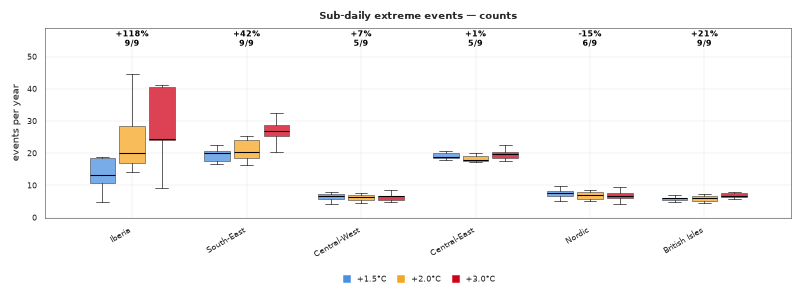

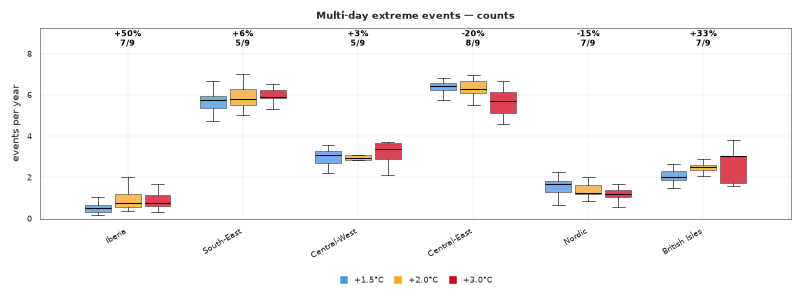

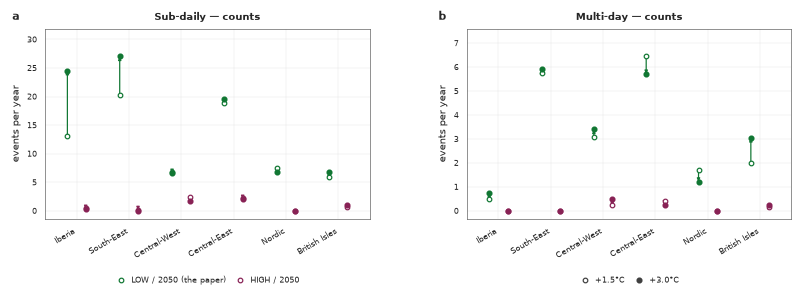

In [13]:
render_currency("counts")

### Option 1B · severity normalised to threshold-hours

**Reads:** "hours of a full-threshold deficit per year" — severity divided by the zone's own
threshold. Iberia sub-daily 29.0 → 77.8. Comparability is restored, the zone ranking matches counts,
and every robust claim survives with a larger magnitude.

**Trade-off.** The unit is compound and has to be defined before it can be read; "77.8
threshold-hours" is not a quantity a reader arrives with. The multi-day axis still spans 21.8×
against counts' 12.9×, and the sentence *"83 % of extreme events are sub-daily"* — one of the
cleanest statements in the paper and the direct justification for the duration split — becomes
unsayable, because the panel no longer counts anything.


  set1_fig3a_threshold_hours   179.9 x  63.8 mm   panel 43.4 mm   pdf 36 kB  png 107 kB
  set1_fig4a_threshold_hours   179.9 x  63.8 mm   panel 43.4 mm   pdf 35 kB  png 104 kB
  set1_fig6_threshold_hours    179.9 x  64.1 mm   panel 43.7 mm   pdf 53 kB  png 164 kB


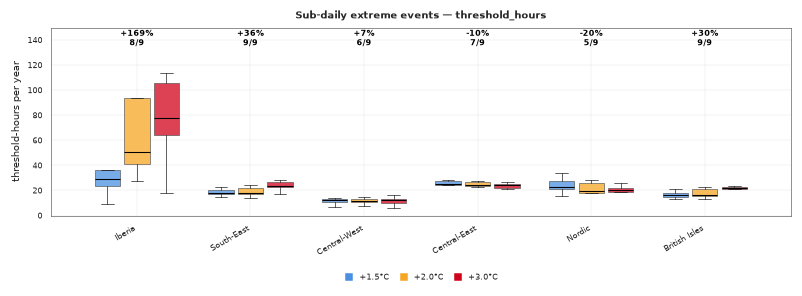

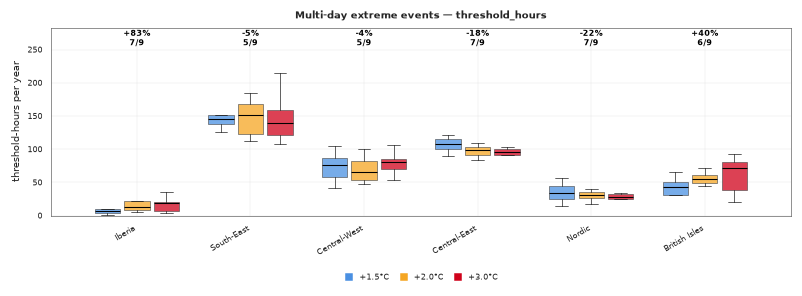

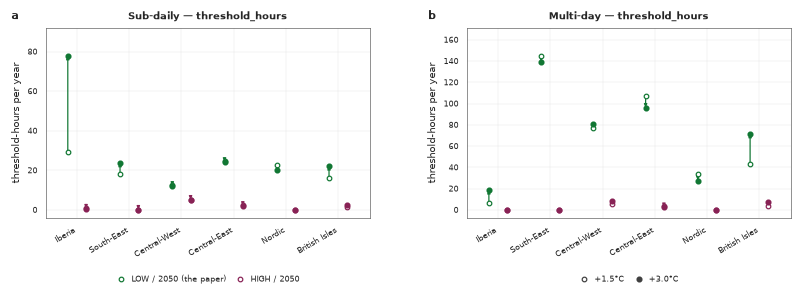

In [15]:
render_currency("threshold_hours")

### Option 1C · severity in raw GWh — *not recommended*

**Reads:** the literal form of the suggestion, and the reason the other two exist.

**Trade-off, and it is a defect rather than a cost.** Severity in GWh scales with zone size, so the
panel ranks zones by how big they are as much as by how stressed they are. Central-West posts
**11 631 GWh yr⁻¹** of multi-day severity against South-East's **6 382**, while by counts
(3.4 against 5.9 per year) and by threshold-relative burden (80 against 140 hours) South-East is
clearly the harder-pressed of the two. The figure would present Europe's least-troubled large zone
as its worst. The multi-day axis also spans **68×**, which needs a log scale, and a log scale on a
change panel makes equal-ratio moves look equal when the paper's claims are about absolute counts.


  set1_fig3a_severity_gwh      179.9 x  63.4 mm   panel 43.1 mm   pdf 52 kB  png 118 kB
  set1_fig4a_severity_gwh      179.9 x  63.2 mm   panel 42.8 mm   pdf 52 kB  png 117 kB
  set1_fig6_severity_gwh       179.9 x  63.5 mm   panel 43.1 mm   pdf 54 kB  png 172 kB


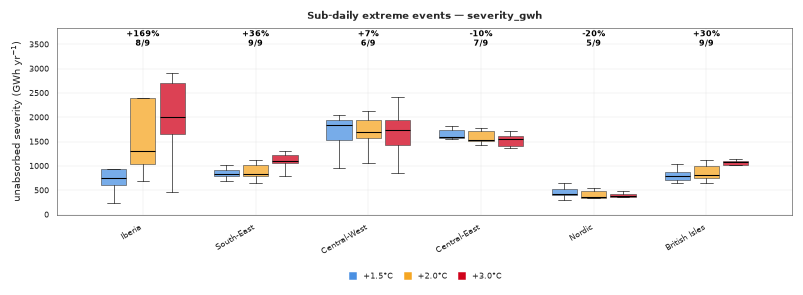

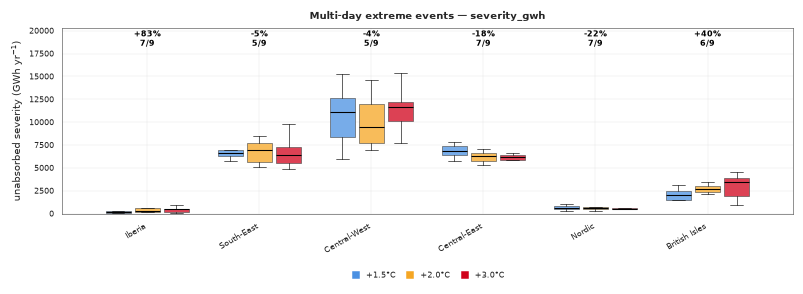

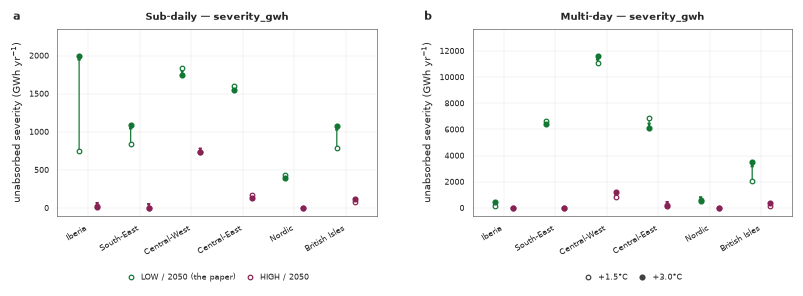

In [17]:
render_currency("severity_gwh")

## 2 · What fills Figure 5's panel b?

The review says the Europe-aggregate severity total does not earn its place. It is right that the
panel as drawn is weak — it aggregates away the zone axis panel a spends its whole width on, and its
only change statistic is a null. The question is whether to replace it or to drop it.


In [19]:
def figure5_option(with_panel_b):
    columns = 2 if with_panel_b else 1
    fig, axes = plt.subplots(1, columns, figsize=(WIDTH, PANEL_ROW_MM * MM), squeeze=False,
                             gridspec_kw={"wspace": 0.30,
                                          "width_ratios": (1.4, 0.6) if with_panel_b else None})
    axes = list(axes[0])
    panel_storage_stack(axes[0], storage_attenuation, STYLE,
                        group_by=("duration_class", list(DURATION_BINS),
                                  [CLASS_LABELS[c] for c in DURATION_BINS]),
                        where={"period": WARMEST}, level_label=WARMEST)
    axes[0].set_title("Absorbed share by zone and duration class", fontsize=6.5, fontweight="bold")
    drawn = None
    if with_panel_b:
        # Pooled over zones AND both duration classes, binned on LENGTH: the question is whether
        # storage's capability depends on the timescale, which is what the class split asserts and
        # what no panel in the paper currently shows.
        drawn = panel_binned_attenuation(axes[1], storage_events, None, STYLE,
                                         duration_class=None, n_bins=6,
                                         bin_column="duration_h",
                                         xlabel="event duration (h)")
        axes[1].set_title("Absorbed share against event duration", fontsize=6.5, fontweight="bold")
    fit_width(fig)
    legend_below(fig, axes[0], *storage_handles(STYLE), ncol=2)
    if with_panel_b:
        legend_below(fig, axes[1], *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, list(zip("ab", axes)))
    return fig, drawn


### Option 2A · replace it with attenuation against event duration

**What it adds.** Median per-event absorbed share falls monotonically with event length — about
95 % on events under six hours to about 57 % on events of eight to sixteen days. That is the
*mechanism* behind the paper's duration split: storage covers short events and cannot span long
ones. Nothing in the paper currently shows it, and it is the panel that makes "sub-daily against
multi-day" a physical distinction rather than a reporting convention.

**Trade-off.** It pools the zones, so like the panel it replaces it gives up the zone axis; the
band widens on the long bins because few events land there, and that honesty costs some visual
crispness. It also puts a second duration-binned panel in the paper if set 3's replacement is also
adopted — the two answer different questions on the same x axis (*where the events are* against
*what storage does about them*), but they should not sit in adjacent figures without the captions
saying so.


  set2_fig5_with_duration_panel 179.8 x  59.4 mm   panel 40.2 mm   pdf 41 kB  png 198 kB

Median absorbed share by event duration, Europe:

period          +1.5°C  +2.0°C  +3.0°C
bin                                   
(2.999, 6.0]      94.9    95.0    95.2
(6.0, 9.0]        90.7    91.4    91.7
(9.0, 12.0]       85.6    84.9    87.2
(12.0, 15.0]      85.8    82.0    83.1
(15.0, 33.0]      74.8    74.1    76.1
(33.0, 1152.0]    56.1    56.4    57.3

Shortest bin to longest, per warming level (percentage points): +1.5°C -38.9, +2.0°C -38.6, +3.0°C -37.9


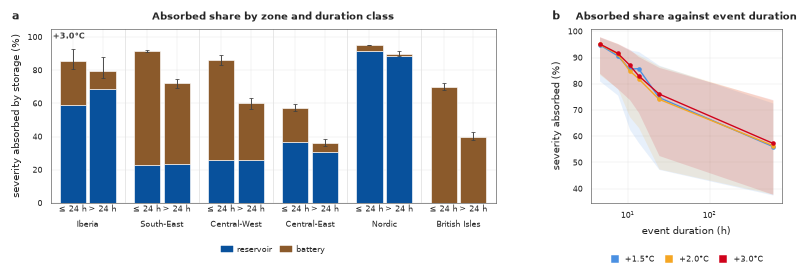

In [21]:
with publication_rc():
    _fig, duration_attenuation = figure5_option(True)
    save(_fig, "set2_fig5_with_duration_panel", FIGS)
plt.show()

print("\nMedian absorbed share by event duration, Europe:\n")
print(duration_attenuation.round(1).to_string())
_delta = duration_attenuation.iloc[-1] - duration_attenuation.iloc[0]
print("\nShortest bin to longest, per warming level (percentage points): "
      + ", ".join(f"{p} {_delta[p]:+.1f}" for p in period_names if p in duration_attenuation))

### Option 2B · drop it — Figure 5 becomes one panel

**What it costs nothing.** The Europe severity totals and the composition shift are already in
Table 2, so no number is lost, and the figure gets shorter and unambiguously about one thing.

**Trade-off.** The paper then never shows *why* the duration split matters for adequacy — only
that absorption differs between two bins, which a reader may reasonably read as an artefact of
where the bin boundary was drawn. It also leaves Figure 5 as the only single-panel main figure,
which is fine on its own but makes the storage result look slighter than the rest.


  set2_fig5_one_panel          179.9 x  57.7 mm   panel 40.8 mm   pdf 37 kB  png 93 kB


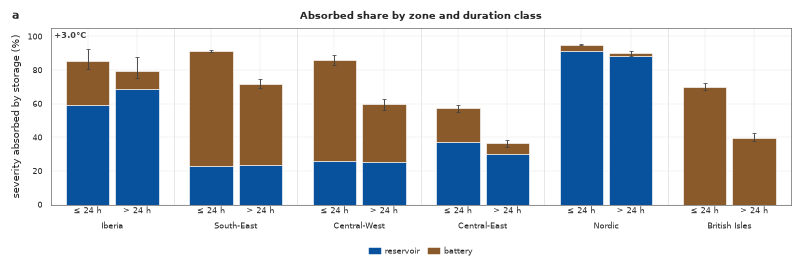

In [23]:
with publication_rc():
    _fig, _ = figure5_option(False)
    save(_fig, "set2_fig5_one_panel", FIGS)
plt.show()

## 3 · What does Figure 2 do?

The review offers panel b's four concrete fixes *or* replacing the panel outright with a duration
distribution. The four fixes are already in the paper, so the comparison below is against the
panel's best form rather than the one that was reviewed.


In [25]:
DURATION_EDGES = [0, 6, 12, 24, 48, 96, 192, 384, 1e4]
DURATION_BIN_LABELS = ["0-6 h", "6-12 h", "12-24 h", "1-2 d", "2-4 d", "4-8 d", "8-16 d", "> 16 d"]
EVENING_SEASONS = ("DJF", "JJA")

# `hours_yr` is frequency x mean duration, the burden panel's currency. The SI notebook adds it in
# its own exceedance cell, which this notebook does not copy.
events_by_season_hours = events_by_season.assign(
    hours_yr=events_by_season["freq_per_year"] * events_by_season["avg_duration_h"])


def duration_spectrum(per_event, value):
    """Events (or severity) per chain-year in each duration bin, per chain."""
    rows = []
    for (model, period), block in per_event.groupby(["model", "period"]):
        years = 20.0
        for lo, hi, label in zip(DURATION_EDGES[:-1], DURATION_EDGES[1:], DURATION_BIN_LABELS):
            inside = block[(block.duration_h > lo) & (block.duration_h <= hi)]
            rows.append(dict(model=model, period=period, bin=label,
                             value=(len(inside) if value == "counts"
                                    else inside.sev_actual.sum() / 1e3) / years))
    return pd.DataFrame(rows)


### Option 3A · keep panel b, with the four fixes — *what the paper does now*

Ordered by duration class first, one y limit shared within each class, the long class in days, and
a thin-bar inter-quartile range with the median as a rule.

**What it does well.** It is the only panel in the paper that resolves the burden by **zone**, and
the zonal spread is the point: South-East carries about 24 days per year of multi-day winter burden
against the British Isles' 2. The class-major ordering makes the seasons comparable within a class,
which is what the review asked for.

**Trade-off.** Four sub-panels of six zones is 24 bar groups for one statement, and the shared
within-class scale — correct as a comparison — squashes the summer sub-daily panel to near nothing,
because winter is several times larger. It also says nothing about *why* 24 hours is the boundary:
the split is imposed on the panel rather than justified by it.


  set3_fig2b_current           179.9 x  73.2 mm   panel 49.1 mm   pdf 18 kB  png 179 kB


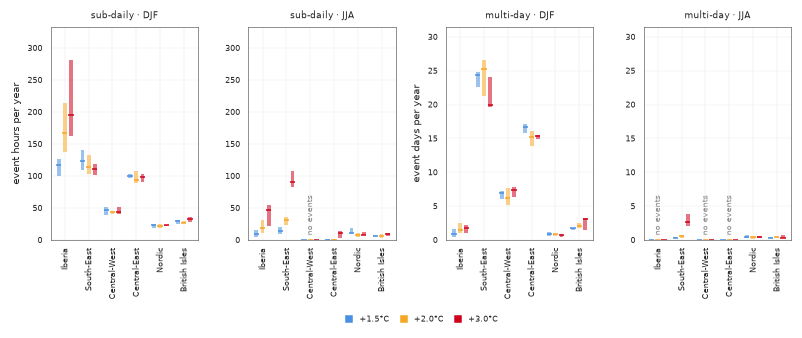

In [27]:
def figure2b_current():
    """Panel b as the paper now draws it, for a like-for-like comparison."""
    fig, axes = plt.subplots(1, 4, figsize=(WIDTH, 52 * MM), gridspec_kw={"wspace": 0.34})
    panel_zone_duration_hours(list(axes), events_by_season_hours, STYLE,
                              list(EVENING_SEASONS), DURATION_LABELS)
    fit_width(fig)
    legend_below(fig, list(axes), *gwl_handles(STYLE), ncol=3)
    return fig


with publication_rc():
    save(figure2b_current(), "set3_fig2b_current", FIGS)
plt.show()

### Option 3B · replace it with the duration spectrum

Counts and severity against event duration, both warming levels, with the 24 h class boundary
marked.

**What it does that nothing else in the paper does.** It shows the two currencies **inverting**
across the boundary — the count distribution peaks below 24 h and the energy distribution peaks at
two to four days — and it shows that the growth under warming is almost entirely in the short bins.
That is the paper's title stated in one panel, and it turns the duration split from a convention
into an observation.

**Trade-off.** It aggregates the zones away, and the zonal spread is a genuine result that would
then appear only in Figures 3 and 4. It also spends the panel on a *framing* statement rather than
a finding about warming, which is a legitimate thing for a methods-flavoured Figure 2 to do but is a
change in that figure's job. And the 24 h boundary is shown to be a smooth point in a smooth
distribution — the curves do not break there — so the panel makes the split defensible without
making it natural, which the caption has to say out loud.


  set3_fig2b_duration_spectrum 179.9 x  72.3 mm   panel 49.5 mm   pdf 38 kB  png 295 kB

Share of events and of severity either side of 24 h:

  +1.5°C  events 78.7% sub-daily / 21.3% multi-day   severity 18.9% / 81.1%
  +3.0°C  events 83.4% sub-daily / 16.6% multi-day   severity 23.1% / 76.9%

Events per year by duration bin (median across chains):

period   +1.5°C  +2.0°C  +3.0°C
bin                            
0-6 h     25.05   25.45   30.90
6-12 h    21.00   23.00   30.70
12-24 h   25.45   30.00   33.75
1-2 d      8.45    9.10    8.90
2-4 d      6.85    6.60    6.95
4-8 d      3.30    3.25    3.25
8-16 d     0.80    0.75    0.70
> 16 d     0.10    0.20    0.15

sub-daily bins : all grow = True, total +23.85 events/yr
multi-day bins : all fall = False, total +0.45 events/yr

A difference of MAGNITUDE, not of sign: the three sub-daily bins add +23.8 events per year between them while the five multi-day bins add +0.5. Do not write 'every multi-day bin falls' — the 1-2 day bin rises.


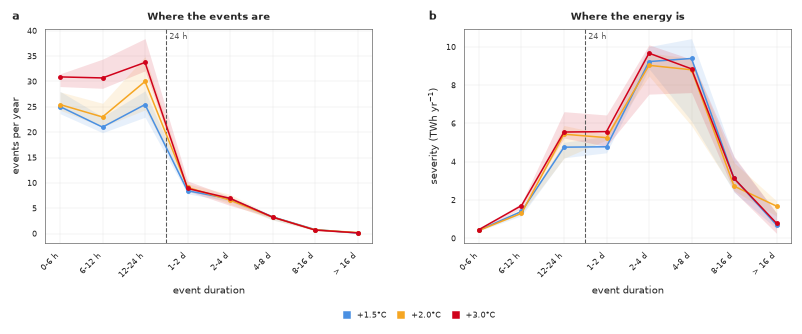

In [29]:
def figure2b_replacement():
    """Counts and severity against duration, with the class boundary marked."""
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 52 * MM), gridspec_kw={"wspace": 0.28})
    positions = np.arange(len(DURATION_BIN_LABELS))
    boundary = DURATION_BIN_LABELS.index("12-24 h") + 0.5
    for ax, value, label in zip(axes, ("counts", "severity"),
                                ("events per year", "severity (TWh yr$^{-1}$)")):
        spectrum = duration_spectrum(storage_events, value)
        for period in period_names:
            block = spectrum[spectrum.period == period]
            median = [block[block.bin == b]["value"].median() for b in DURATION_BIN_LABELS]
            low = [block[block.bin == b]["value"].quantile(0.25) for b in DURATION_BIN_LABELS]
            high = [block[block.bin == b]["value"].quantile(0.75) for b in DURATION_BIN_LABELS]
            ax.fill_between(positions, low, high, color=STYLE.gwl_colors[period], alpha=0.13, lw=0)
            ax.plot(positions, median, "-o", ms=2.2, lw=1.0, color=STYLE.gwl_colors[period],
                    label=period)
        ax.axvline(boundary, color="0.35", lw=0.7, ls="--", zorder=1)
        ax.annotate("24 h", xy=(boundary, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(2, -2), textcoords="offset points", ha="left", va="top",
                    fontsize=5, color="0.35")
        ax.set_xticks(positions)
        ax.set_xticklabels(DURATION_BIN_LABELS, fontsize=5, rotation=45, ha="right")
        ax.set_ylabel(label, fontsize=6.5)
        ax.set_xlabel("event duration", fontsize=6.5)
        ax.tick_params(labelsize=5)
    axes[0].set_title("Where the events are", fontsize=6.5, fontweight="bold")
    axes[1].set_title("Where the energy is", fontsize=6.5, fontweight="bold")
    fit_width(fig)
    legend_below(fig, list(axes), *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, list(zip("ab", axes)))
    return fig


with publication_rc():
    save(figure2b_replacement(), "set3_fig2b_duration_spectrum", FIGS)
plt.show()

print("\nShare of events and of severity either side of 24 h:\n")
for _period in (REFERENCE, WARMEST):
    _block = storage_events[storage_events.period == _period]
    _sub = _block.duration_h <= 24
    print(f"  {_period}  events {_sub.mean():5.1%} sub-daily / {1 - _sub.mean():5.1%} multi-day"
          f"   severity {_block[_sub].sev_actual.sum() / _block.sev_actual.sum():5.1%} / "
          f"{_block[~_sub].sev_actual.sum() / _block.sev_actual.sum():5.1%}")

_counts = duration_spectrum(storage_events, "counts")
_wide = _counts.pivot_table(index="bin", columns="period", values="value", aggfunc="median")
_wide = _wide.reindex(DURATION_BIN_LABELS)
print("\nEvents per year by duration bin (median across chains):\n")
print(_wide.round(2).to_string())

# What is actually true, rather than the tidier claim: the SUB-DAILY bins grow substantially and
# the multi-day ones move very little. "Every multi-day bin falls" is NOT true — the 1-2 day bin
# rises — so the statement is made in terms of the SIZE of the move.
_sub_growth = _wide.loc[DURATION_BIN_LABELS[:3], WARMEST] - _wide.loc[DURATION_BIN_LABELS[:3], REFERENCE]
_multi_growth = _wide.loc[DURATION_BIN_LABELS[3:], WARMEST] - _wide.loc[DURATION_BIN_LABELS[3:], REFERENCE]
print(f"\nsub-daily bins : all grow = {bool((_sub_growth > 0).all())}, "
      f"total {_sub_growth.sum():+.2f} events/yr")
print(f"multi-day bins : all fall = {bool((_multi_growth < 0).all())}, "
      f"total {_multi_growth.sum():+.2f} events/yr")
print("\nA difference of MAGNITUDE, not of sign: the three sub-daily bins add "
      f"{_sub_growth.sum():+.1f} events per year between them while the five multi-day bins add "
      f"{_multi_growth.sum():+.1f}. Do not write 'every multi-day bin falls' — the 1-2 day bin rises.")
assert _sub_growth.sum() > 10 * abs(_multi_growth.sum()), \
    "the sub-daily growth no longer dwarfs the multi-day move; the panel's claim needs restating"

In [30]:
# ── Quantities sets 3C, 4 and 5 share, built once ───────────────────────────────────────
# Annual demand per zone per chain: the only denominator with a meaning a reader already holds, and
# the closest thing available to "per capita" — there is no population series in this repository,
# because population enters the demand model folded into per-country coefficients and is never
# exposed per zone. Normalising by what the system must SERVE is arguably the better quantity
# anyway.
_demand = {}
for _model, _ds in main["components"].items():
    for _period in (REFERENCE, WARMEST):
        _window = resolve_model_periods(period_defs, _model).get(_period)
        if _window is None:
            continue
        for _zone in zones:
            _block = _ds["total_demand"].sel(zone=_zone, time=slice(*_window))
            _years = pd.DatetimeIndex(_block["time"].values).year.nunique()
            _demand[(_model, _period, _zone)] = float(np.nansum(_block.values)) / _years   # energy per step: no x3 (fixed with the severity source fix)

events_norm = events_annual.assign(
    hours_yr=events_annual.freq_per_year * events_annual.avg_duration_h,
    thr=[THRESHOLD_GWH[r.zone] for r in events_annual.itertuples()],
    demand_gwh=[_demand.get((r.model, r.period, r.zone), np.nan)
                for r in events_annual.itertuples()],
)
events_norm = events_norm.assign(
    sev_per_event_x_thr=events_norm.avg_severity_gwh / events_norm.thr,
    sev_threshold_hours=events_norm.total_annual_severity_gwh / events_norm.thr * TIME_STEP_H,
    sev_pct_of_demand=events_norm.total_annual_severity_gwh / events_norm.demand_gwh * 100,
    sev_per_event_hour=events_norm.total_annual_severity_gwh
    / events_norm.hours_yr.replace(0, np.nan),
)

#: Every candidate denominator, with the label its axis would carry.
NORMALISERS = {
    "counts": ("freq_per_year", "events per year"),
    "raw GWh": ("total_annual_severity_gwh", "severity (GWh yr$^{-1}$)"),
    "per event": ("avg_severity_gwh", "severity per event (GWh)"),
    "per event × threshold": ("sev_per_event_x_thr", "severity per event (× threshold)"),
    "per event-hour": ("sev_per_event_hour", "severity per event-hour (GWh h⁻¹)"),
    "threshold-hours": ("sev_threshold_hours", "threshold-hours per year"),
    "% of demand": ("sev_pct_of_demand", "severity (% of annual demand)"),
}


def normaliser_report(duration_class="multi_day"):
    """Axis span and zone ranking each denominator produces — the table that decides set 4."""
    rows, counts_order = {}, None
    for name, (column, _label) in NORMALISERS.items():
        spans = {}
        for klass in DURATION_BINS:
            values = [events_norm[(events_norm.zone == z) & (events_norm.duration_class == klass)
                                  & (events_norm.period == p)][column].median()
                      for z in zones for p in (REFERENCE, WARMEST)]
            values = [v for v in values if np.isfinite(v) and v > 0]
            spans[klass] = max(values) / min(values) if values else np.nan
        medians = {z: events_norm[(events_norm.zone == z)
                                  & (events_norm.duration_class == duration_class)
                                  & (events_norm.period == WARMEST)][column].median()
                   for z in zones}
        order = sorted(medians, key=lambda z: -(medians[z] if np.isfinite(medians[z]) else -1))
        counts_order = counts_order or order
        rows[name] = {"sub-daily span": f"{spans['sub_daily']:.1f}x",
                      "multi-day span": f"{spans['multi_day']:.1f}x",
                      "worst multi-day zone": ZONE_LABELS[order[0]],
                      "ranks like counts": "yes" if order == counts_order else "no"}
    return pd.DataFrame(rows).T


NORMALISER_TABLE = normaliser_report()
print("Which denominator fixes the multi-day range, and which keeps the ranking counts give:\n")
print(NORMALISER_TABLE.to_string())
print("\nThe two zones that decide the ranking, multi-day at " + WARMEST + ":")
for _name, (_column, _) in NORMALISERS.items():
    _v = {z: events_norm[(events_norm.zone == z) & (events_norm.duration_class == "multi_day")
                         & (events_norm.period == WARMEST)][_column].median() for z in zones}
    print(f"  {_name:<24} South-East {_v['South_East']:10.2f}   "
          f"Central-West {_v['Central_Western']:10.2f}   "
          f"ratio {_v['South_East'] / _v['Central_Western']:5.2f}")


Which denominator fixes the multi-day range, and which keeps the ranking counts give:

                      sub-daily span multi-day span worst multi-day zone ranks like counts
counts                          4.5x          12.9x           South-East               yes
raw GWh                         5.2x          68.2x         Central-West                no
per event                       6.5x           9.7x         Central-West                no
per event × threshold           3.4x           1.8x           South-East                no
per event-hour                  5.3x           7.9x         Central-West                no
threshold-hours                 6.5x          21.8x           South-East               yes
% of demand                     7.1x          28.1x         Central-East                no

The two zones that decide the ranking, multi-day at +3.0°C:
  counts                   South-East       5.90   Central-West       3.40   ratio  1.74
  raw GWh                  South-Ea

### Option 3C · Figure 2 as four panels — zones, tail, and the duration split

The methods figure the review describes: **a** where the zones are, **b** the tail against the fixed
threshold for the two zones that carry the southern result, **c** and **d** the duration spectrum
from option 3B.

**What it does well.** It answers, in one figure and in order, the three questions a reader has
before Figure 3 can mean anything: *what are these six regions, what is the threshold and does the
tail move against it, and why is the split drawn at 24 hours.* Panel **a** also removes the paper's
dependence on a reader having found S4. Trimming **b** from six zones to two costs little — the
southern zones are where the tail actually moves (Iberia ×6.4 and South-East ×11.2 in summer against
×0.9 to ×1.4 elsewhere) — and buys the width that **c** and **d** need.

**Trade-off.** The zonal burden panel disappears from the main text entirely: the fact that
South-East carries about 24 days per year of multi-day winter deficit against the British Isles' 2
would then appear nowhere outside the SI. Figure 2 also stops being a *results* figure and becomes a
*setup* figure, which is defensible for a Figure 2 but means the paper's first result now arrives at
Figure 3. And the four exceedance ratios that survive in **b** are the only ones shown, so the
non-southern zones' near-flat tails — a genuine null result — go with them.

**Two arrangements are rendered below**, because the map is the part that constrains the layout.
Europe over −12 to 40° of longitude and 33 to 72° of latitude wants a cell about **0.85 as wide as
it is tall** — a degree of longitude is roughly 0.64 of a degree of latitude at 50 °N — and
`set_aspect("auto")` stretches the continent to fill whatever cell it is handed. The first version
of this figure gave it a 1.33 : 1 cell, widening Europe by about 1.6×.

- **A · map beside the survival block.** Map cell ≈ 45 × 65 mm (aspect 0.69). The survival block
  keeps full width and the height its log axes need; **c** and **d** get about 83 mm each.
- **B · map spanning both rows.** Map cell ≈ 52 × 100 mm (aspect 0.52) — the most faithful shape,
  and slightly *taller* than true. The cost lands on the other three: the survival sub-axes drop to
  roughly 58 × 22 mm and **c**/**d** to about 58 mm wide.

In both, the bottom row is nested in its own equal-column grid, so **c** and **d** are exactly the
same size — asserted in the cell rather than eyeballed. Their titles are now `Events by duration`
and `Severity by duration`, matching the convention the rest of the paper uses.

**Each arrangement is swept over four map widths**, because as first rendered *both* were too narrow
rather than too wide: A sat at aspect 0.69 and B at 0.50 against a true 0.85. The table below the
renders gives, for every width, the map cell in mm, its aspect against true shape, what the survival
block and the two spectra are left with, and how many words overlap — so the point at which widening
starts breaking tick labels is visible rather than guessed at.


In [32]:
import re
import subprocess

SOUTHERN_ZONES = ["Iberian_Peninsula", "South_East"]
EVENING_SEASONS = ("DJF", "JJA")

# Country polygons for panel a. Simplified at 0.02 degrees for the same reason Figure 1 does it:
# the panel is ~55 mm wide for 52 degrees of longitude, so the displacement is far below print
# resolution and the vector file halves.
countries_options = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson")
countries_options["geometry"] = countries_options.geometry.simplify(0.02)


def panel_zone_map(ax):
    """The six balancing zones, as S4 draws them."""
    zone_by_iso2 = {iso: zone for zone, members in REALTIME_BALANCING_ZONES.items()
                    for iso in members}
    frame = countries_options.copy()
    frame["zone"] = frame["ISO2"].map(zone_by_iso2)
    frame[frame["zone"].isna()].plot(ax=ax, color="0.90", edgecolor="0.35", linewidth=0.25)
    for zone in zones:
        subset = frame[frame["zone"] == zone]
        if len(subset):
            subset.plot(ax=ax, color=ZONE_COLORS[zone], edgecolor="white", linewidth=0.3)
    ax.set_xlim(-12, 40)
    ax.set_ylim(33, 72)
    ax.set_axis_off()
    ax.set_aspect("auto")
    # `loc` names the part of the legend that lands ON the anchor, so "lower center" at y=-0.13
    # put the legend's BOTTOM 5.9 mm below the axes and let it grow upward, back over southern
    # Europe. "upper center" anchors its top there instead, so it grows downward into free space.
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ZONE_COLORS[z]) for z in zones],
              labels=[ZONE_LABELS[z] for z in zones], fontsize=5, frameon=False, ncol=2,
              loc="upper center", bbox_to_anchor=(0.5, -0.01), handlelength=1.0,
              handletextpad=0.5, columnspacing=1.0)


def panel_southern_survival(axes):
    """2a trimmed to the two southern zones — the same call sequence tail_exceedance_figure makes."""
    for column, zone in enumerate(SOUTHERN_ZONES):
        threshold = float(zone_threshold.sel(zone=zone))
        x = compute_survival_x_grid(main["residual_load"], period_defs, zone,
                                    [SEASON_MONTHS[s] for s in EVENING_SEASONS], period_names,
                                    threshold=threshold)
        for row, season in enumerate(EVENING_SEASONS):
            ax = axes[row][column]
            _, survival = compute_exceedance_survival(
                main["residual_load"], period_defs, zone, SEASON_MONTHS[season], period_names,
                spread=SPREAD, x=x)
            p_ref = compute_exceedance_probability(main["residual_load"], period_defs, zone,
                                                   SEASON_MONTHS[season], REFERENCE, threshold)
            p_warm = compute_exceedance_probability(main["residual_load"], period_defs, zone,
                                                    SEASON_MONTHS[season], WARMEST, threshold)
            survival_axes(ax, survival, x, threshold, STYLE,
                          ratio=(p_warm / p_ref if p_ref > 0 else np.nan), show_legend=False)
            ax.tick_params(labelsize=5)
            if row == 0:
                ax.set_title(ZONE_LABELS[zone], fontsize=6, fontweight="bold")
                # The row below carries the axis; repeating it here puts a tick row in the gap.
                ax.set_xticklabels([])
            else:
                ax.set_xlabel("residual load (GWh / 3 h)", fontsize=6)
            if column == 0:
                ax.set_ylabel(f"{season}\nP(RL > x)", fontsize=6)
            else:
                ax.set_yticklabels([])


def figure2_option_3c(layout="beside", map_share=0.42):
    """Figure 2 as four panels, in one of two arrangements and at any map width.

    The two differ ONLY in where the map sits, because that is the whole question: Europe over
    -12 to 40 degrees of longitude and 33 to 72 of latitude wants a cell about 0.85 as wide as it
    is tall (a degree of longitude is ~0.64 of a degree of latitude at 50 N), and `set_aspect("auto")`
    stretches it to whatever cell it is given. `map_share` is that cell's share of a ratio pair
    summing to 2.0, so it is the one knob the sweep below turns; everything else is fixed.

    Widening helps BOTH arrangements, which is the opposite of what "the map looks squeezed" first
    suggests: as first rendered A sat at 0.69 and B at 0.50 against a true 0.85, so both were too
    NARROW, not too wide. What widening costs differs though — in A the map takes width from the
    survival block alone, in B from the survival block and from c and d together, because they share
    the right-hand column.

    Both nest the bottom row in its own equal-column sub-gridspec. The first version put
    `width_ratios` on the whole 2x2 grid, which applied the top row's 0.78/1.22 split to the bottom
    row as well and left panel c at ~60 mm against panel d at ~94 mm — two panels of the same kind,
    meant to be read together, at a 1.57x size difference.
    """
    if layout == "beside":
        fig = plt.figure(figsize=(WIDTH, 100 * MM))
        outer = gridspec.GridSpec(2, 1, height_ratios=(1.0, 0.66), hspace=0.55, figure=fig)
        top = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0], wspace=0.24,
                                               width_ratios=(map_share, 2.0 - map_share))
        map_cell, survival_spec = top[0], top[1]
        bottom_spec = outer[1]
    else:                                          # "spanning": the map takes the full height
        fig = plt.figure(figsize=(WIDTH, 104 * MM))
        outer = gridspec.GridSpec(1, 2, wspace=0.24,
                                  width_ratios=(map_share, 2.0 - map_share), figure=fig)
        right = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[1], hspace=0.62,
                                                 height_ratios=(1.0, 0.90))
        map_cell, survival_spec = outer[0], right[0]
        bottom_spec = right[1]

    ax_a = fig.add_subplot(map_cell)
    panel_zone_map(ax_a)
    ax_a.set_title("Balancing zones", fontsize=6.5, fontweight="bold")

    survival_cell = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=survival_spec,
                                                     hspace=0.22, wspace=0.10)
    survival = [[fig.add_subplot(survival_cell[r, c]) for c in range(2)] for r in range(2)]
    panel_southern_survival(survival)
    survival[0][0].set_title(ZONE_LABELS[SOUTHERN_ZONES[0]], fontsize=6, fontweight="bold")

    # Nested and equal-columned, so the ratio above cannot reach the two spectrum panels.
    bottom_cell = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=bottom_spec, wspace=0.30)
    bottom = [fig.add_subplot(bottom_cell[0]), fig.add_subplot(bottom_cell[1])]
    positions = np.arange(len(DURATION_BIN_LABELS))
    boundary = DURATION_BIN_LABELS.index("12-24 h") + 0.5
    for ax, value, label in zip(bottom, ("counts", "severity"),
                                ("events per year", "severity (TWh yr$^{-1}$)")):
        spectrum = duration_spectrum(storage_events, value)
        for period in period_names:
            block = spectrum[spectrum.period == period]
            median = [block[block.bin == b]["value"].median() for b in DURATION_BIN_LABELS]
            low = [block[block.bin == b]["value"].quantile(0.25) for b in DURATION_BIN_LABELS]
            high = [block[block.bin == b]["value"].quantile(0.75) for b in DURATION_BIN_LABELS]
            ax.fill_between(positions, low, high, color=STYLE.gwl_colors[period], alpha=0.13, lw=0)
            ax.plot(positions, median, "-o", ms=2.2, lw=1.0, color=STYLE.gwl_colors[period],
                    label=period)
        ax.axvline(boundary, color="0.35", lw=0.7, ls="--", zorder=1)
        ax.annotate("24 h", xy=(boundary, 1.0), xycoords=("data", "axes fraction"),
                    xytext=(2, -2), textcoords="offset points", ha="left", va="top",
                    fontsize=5, color="0.35")
        ax.set_xticks(positions)
        ax.set_xticklabels(DURATION_BIN_LABELS, fontsize=5, rotation=45, ha="right")
        ax.set_ylabel(label, fontsize=6.5)
        ax.set_xlabel("event duration", fontsize=6.5)
        ax.tick_params(labelsize=5)
    # The convention the rest of the paper now uses: the title names the quantity and the y-label
    # carries the unit. "Where the events are" / "Where the energy is" were message titles left
    # over from before Figures 3-6 were converted.
    bottom[0].set_title("Events by duration", fontsize=6.5, fontweight="bold")
    bottom[1].set_title("Severity by duration", fontsize=6.5, fontweight="bold")

    fit_width(fig)
    legend_below(fig, bottom, *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, [("a", ax_a), ("b", survival[0][0]),
                        ("c", bottom[0]), ("d", bottom[1])])
    return fig


# 0.50 is in the list because the first sweep straddled the optimum without landing on it: at 0.42
# the map came out 15 % too narrow and at 0.58 17 % too wide. The map's HEIGHT is fixed by the
# layout (44.9 mm in A, 103.3 mm in B), so true shape needs 0.85 x that height in width — about
# 38 mm in A, and about 88 mm in B, which is half the page and out of reach here.
MAP_SHARES = (0.42, 0.50, 0.58, 0.74, 0.90)
TRUE_ASPECT = 0.85          # Europe's width:height at 50 N, the shape the cell should aim at


def measure(fig, path):
    """Panel geometry in mm, and how many words overlap in the saved PDF."""
    width_mm, height_mm = (s * 25.4 for s in fig.get_size_inches())
    ax_map, survival_first = fig.axes[0], fig.axes[1]
    spectrum = fig.axes[-2]
    box = ax_map.get_position()
    text = subprocess.run(["pdftotext", "-bbox", str(path), "-"],
                          capture_output=True, text=True).stdout
    words = [(float(a), float(b), float(c), float(d)) for a, b, c, d in
             re.findall(r'<word xMin="([\d.]+)" yMin="([\d.]+)" xMax="([\d.]+)" yMax="([\d.]+)"',
                        text)]
    collisions = 0
    for i, a in enumerate(words):
        for b in words[i + 1:]:
            if not (a[2] <= b[0] or b[2] <= a[0] or a[3] <= b[1] or b[3] <= a[1]):
                overlap = (min(a[2], b[2]) - max(a[0], b[0])) * (min(a[3], b[3]) - max(a[1], b[1]))
                area = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
                if area > 0 and overlap / area > 0.10:
                    collisions += 1
    map_w, map_h = box.width * width_mm, box.height * height_mm
    return {
        "map w (mm)": round(map_w, 1),
        "map h (mm)": round(map_h, 1),
        "aspect": round(map_w / map_h, 2),
        "vs true": f"{map_w / map_h / TRUE_ASPECT:.2f}x",
        "survival (mm)": round(survival_first.get_position().width * width_mm, 1),
        "c/d (mm)": round(spectrum.get_position().width * width_mm, 1),
        "collisions": collisions,
    }


rows = {}
with publication_rc():
    for _layout, _tag in (("beside", "A"), ("spanning", "B")):
        for _share in MAP_SHARES:
            _fig = figure2_option_3c(_layout, map_share=_share)
            # The defect this sweep must not reintroduce: c and d are the same kind of plot and must
            # stay the same size at every width. `_panel_letters` records them last, in draw order.
            _c, _d = _fig.axes[-2].get_position().width, _fig.axes[-1].get_position().width
            assert abs(_c - _d) < 1e-9, \
                f"{_layout} at map_share={_share}: c and d differ ({_c:.4f} vs {_d:.4f})"
            _stem = f"set3C_{_tag}_map{int(_share * 100):03d}"
            save(_fig, _stem, FIGS)
            rows[f"{_tag} · {_share:.2f}"] = measure(_fig, FIGS / f"{_stem}.pdf")
    plt.close("all")

MAP_SWEEP = pd.DataFrame(rows).T
print("\nWhat the map width buys and what it costs. `vs true` of 1.00 is correct shape;")
print("below 1 the continent is squeezed narrow, above 1 it is stretched wide.\n")
print(MAP_SWEEP.to_string())
_clean = MAP_SWEEP[MAP_SWEEP["collisions"] == 0]
print(f"\n{len(_clean)} of {len(MAP_SWEEP)} widths render without text collisions.")
if len(_clean):
    _best = (_clean["aspect"].astype(float) / TRUE_ASPECT - 1).abs().idxmin()
    print(f"Closest to true shape among those: {_best} "
          f"(aspect {MAP_SWEEP.loc[_best, 'aspect']}, {MAP_SWEEP.loc[_best, 'vs true']})")

print("Exceedance ratio at the threshold, +1.5 to +3.0 (what panel b annotates):")
for _zone in SOUTHERN_ZONES:
    _thr = float(zone_threshold.sel(zone=_zone))
    for _season in EVENING_SEASONS:
        _ref = compute_exceedance_probability(main["residual_load"], period_defs, _zone,
                                              SEASON_MONTHS[_season], REFERENCE, _thr)
        _warm = compute_exceedance_probability(main["residual_load"], period_defs, _zone,
                                               SEASON_MONTHS[_season], WARMEST, _thr)
        print(f"  {ZONE_LABELS[_zone]:<12}{_season}  x{_warm / _ref:.1f}" if _ref > 0
              else f"  {ZONE_LABELS[_zone]:<12}{_season}  n/a")

  set3C_A_map042               179.9 x 118.0 mm   panel 44.9 mm   pdf 202 kB  png 631 kB
  set3C_A_map050               179.9 x 118.0 mm   panel 44.9 mm   pdf 202 kB  png 640 kB
  set3C_A_map057               179.9 x 118.0 mm   panel 44.9 mm   pdf 203 kB  png 647 kB
  set3C_A_map074               179.9 x 118.0 mm   panel 44.9 mm   pdf 203 kB  png 657 kB
  set3C_A_map090               179.9 x 118.0 mm   panel 44.9 mm   pdf 204 kB  png 664 kB
  set3C_B_map042               180.0 x 126.2 mm   panel 103.3 mm   pdf 204 kB  png 717 kB
  set3C_B_map050               180.0 x 126.2 mm   panel 103.3 mm   pdf 204 kB  png 730 kB
  set3C_B_map057               180.0 x 126.2 mm   panel 103.3 mm   pdf 205 kB  png 740 kB
  set3C_B_map074               180.0 x 126.2 mm   panel 103.3 mm   pdf 206 kB  png 754 kB
  set3C_B_map090               180.0 x 126.2 mm   panel 103.3 mm   pdf 206 kB  png 764 kB

What the map width buys and what it costs. `vs true` of 1.00 is correct shape;
below 1 the continent is 

## 4 · Counts and severity together, or severity normalised

Set 1 asked which single currency should carry the per-zone panels. The review's follow-up offers
two ways out of choosing: **use both**, or **normalise severity** so that its problem — which is
concentrated in the multi-day class — goes away.

The table printed above decides most of this. Read it before the panels: only denominators that
divide by the **zone's own p95 threshold** remove the zone-size effect. Every other one still ranks
Central-West as Europe's worst multi-day zone, because its events are individually enormous even
though it has fewer of them than the South-East.


### Option 4A · both currencies, as a decomposition

Severity ≈ **counts × depth per event**. Drawing both terms side by side is not two views of one
quantity; it is the quantity factorised, and the two factors behave completely differently.

**What it shows.** The left panel moves — Iberia +118 % — and the right panel barely does.
`doc/paper_summary.md` §3.6 already records why: only Iberia's per-event depth shifts (+24 %), every
other zone sits between −11 % and +2 %. So the figure says *the burden grows because events multiply,
not because they deepen*, which is a stronger statement than either panel alone and is the honest
answer to "should we use counts or severity".

**Trade-off.** It spends a whole panel on a quantity that is nearly flat, which is expensive if the
reader does not realise flatness is the finding — the caption has to say so explicitly. Per-event
depth in threshold units is also the least familiar quantity in the paper, and it is a *conditional*
mean: it says nothing about how often the condition occurs, so it must never be read on its own.


  set4A_counts_and_depth_sub_daily 179.9 x  64.1 mm   panel 43.8 mm   pdf 64 kB  png 177 kB
  set4A_counts_and_depth_multi_day 179.9 x  64.4 mm   panel 44.0 mm   pdf 64 kB  png 176 kB
The factorisation, paired change +1.5 -> +3.0 (%):

  zone           class                 count   depth per event
  Iberia         sub_daily         +118% 9/9          +38% 7/9
  South-East     sub_daily          +42% 9/9           -7% 6/9
  Central-West   sub_daily           +7% 5/9           +1% 5/9
  Central-East   sub_daily           +1% 5/9           -9% 8/9
  Nordic         sub_daily          -15% 6/9           -9% 6/9
  British Isles  sub_daily          +21% 9/9           +3% 5/9
  Iberia         multi_day          +50% 7/9          +21% 6/9
  South-East     multi_day           +6% 5/9           -2% 5/9
  Central-West   multi_day           +3% 5/9           -3% 6/9
  Central-East   multi_day          -20% 8/9           -3% 5/9
  Nordic         multi_day          -15% 7/9           +3% 5/9
  Britis

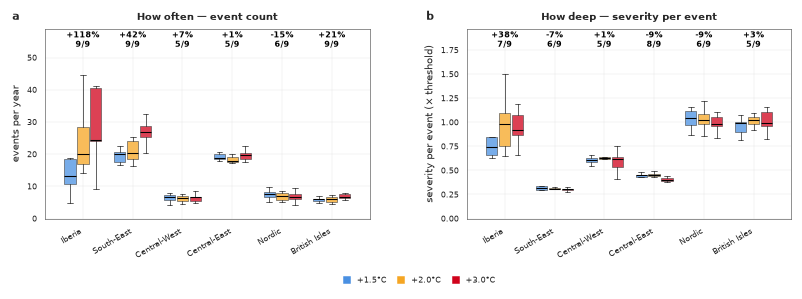

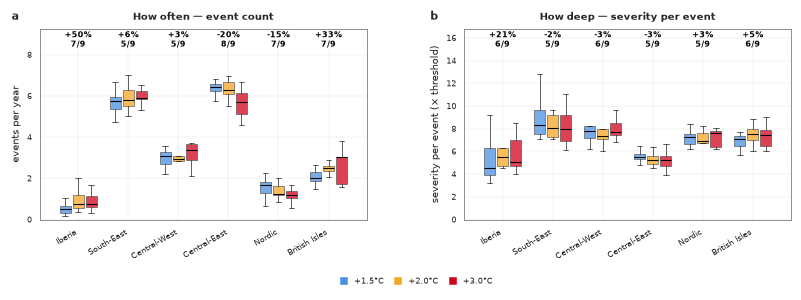

In [35]:
def figure_counts_and_depth(duration_class):
    """The factorisation: how often, beside how deep each one is."""
    fig, axes = plt.subplots(1, 2, figsize=(WIDTH, 46 * MM), gridspec_kw={"wspace": 0.30})
    for ax, (column, label, title) in zip(axes, [
            ("freq_per_year", "events per year", "How often — event count"),
            ("sev_per_event_x_thr", "severity per event (× threshold)",
             "How deep — severity per event")]):
        panel_event_frequency(ax, events_norm, duration_class, STYLE, label,
                              value_column=column, annotation_color="black")
        ax.set_title(title, fontsize=6.5, fontweight="bold")
    fit_width(fig)
    legend_below(fig, list(axes), *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, list(zip("ab", axes)))
    return fig


with publication_rc():
    for _class in DURATION_BINS:
        save(figure_counts_and_depth(_class), f"set4A_counts_and_depth_{_class}", FIGS)
plt.show()

print("The factorisation, paired change +1.5 -> +3.0 (%):\n")
print(f"  {'zone':<15}{'class':<11}{'count':>16}{'depth per event':>18}")
for _class in DURATION_BINS:
    for _zone in zones:
        _cells = []
        for _column in ("freq_per_year", "sev_per_event_x_thr"):
            _rows = events_norm[(events_norm.zone == _zone)
                                & (events_norm.duration_class == _class)]
            _a = _rows[_rows.period == REFERENCE].set_index("model")[_column]
            _b = _rows[_rows.period == WARMEST].set_index("model")[_column]
            _i = [m for m in _a.index.intersection(_b.index) if _a[m] > 0]
            _chg = ((_b.loc[_i] - _a.loc[_i]) / _a.loc[_i] * 100).median() if _i else np.nan
            _n = int((np.sign(_b.loc[_i] - _a.loc[_i]) == np.sign(_chg)).sum()) if _i else 0
            _cells.append(f"{_chg:+7.0f}% {_n}/9")
        print(f"  {ZONE_LABELS[_zone]:<15}{_class:<11}{_cells[0]:>16}{_cells[1]:>18}")
print("\nThe count term carries the signal; the depth term is close to invariant outside Iberia. "
      "That contrast IS the result, and a caption must say so or the right panel reads as filler.")

### Option 4B · severity normalised, four ways

The same multi-day panel under four denominators, so the table above can be checked against the
artwork. **Raw GWh is included as the control** — it is the one that fails.

**What each costs.**

- **raw GWh yr⁻¹** — ranks Central-West above the South-East and spans 68×. Not usable.
- **per event × threshold** — the tightest quantity in the paper, a 1.8× span, and it agrees with
  counts on which zone is worst. But it is a per-event conditional mean, so it drops frequency
  entirely; it belongs beside a count panel (option 4A), not instead of one.
- **threshold-hours per year** — the only *total* that reproduces the counts ranking exactly. Costs
  a compound unit that has to be defined before the panel can be read.
- **% of annual demand** — the most interpretable unit and the closest available stand-in for per
  capita. It reorders the top zone, putting Central-East above the South-East, because it divides by
  a denominator that is unrelated to how the threshold was set.


  set4B_normalised_severity_multi_day 179.9 x  74.8 mm   panel 47.7 mm   pdf 79 kB  png 306 kB

Control behaves as claimed: raw GWh mis-ranks, threshold-hours does not.


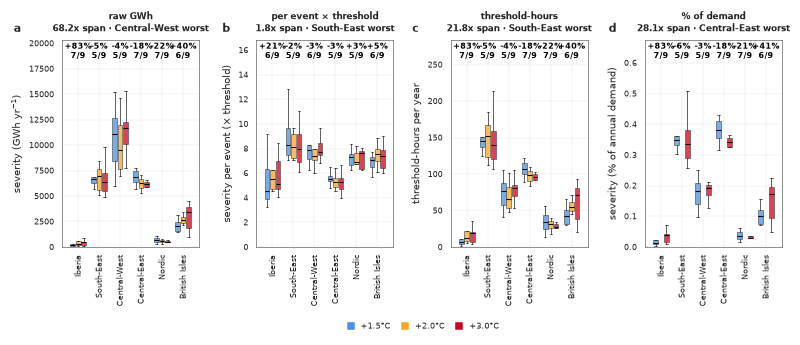

In [37]:
def figure_normalised_severity(duration_class="multi_day"):
    """One panel per denominator, on the class where severity's range problem lives."""
    shown = ["raw GWh", "per event × threshold", "threshold-hours", "% of demand"]
    fig, axes = plt.subplots(1, len(shown), figsize=(WIDTH, 52 * MM),
                             gridspec_kw={"wspace": 0.42})
    for ax, name in zip(axes, shown):
        column, label = NORMALISERS[name]
        # 90 degrees: four panels across 180 mm leaves a 6.7 mm zone slot, and "Central-West"
        # rotated 30 degrees spans 9.2 mm, so neighbouring names overlapped.
        panel_event_frequency(ax, events_norm, duration_class, STYLE, label,
                              value_column=column, annotation_color="black", rotation=90)
        row = NORMALISER_TABLE.loc[name]
        ax.set_title(f"{name}\n{row['multi-day span']} span · {row['worst multi-day zone']} worst",
                     fontsize=6, fontweight="bold")
    fit_width(fig)
    legend_below(fig, list(axes), *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, list(zip("abcd", axes)))
    return fig


with publication_rc():
    save(figure_normalised_severity(), "set4B_normalised_severity_multi_day", FIGS)
plt.show()

# The control must actually fail, or the panel is not making the point it claims to.
assert NORMALISER_TABLE.loc["raw GWh", "ranks like counts"] == "no", \
    "raw GWh no longer mis-ranks the zones; set 4B's argument needs rewriting"
assert NORMALISER_TABLE.loc["threshold-hours", "ranks like counts"] == "yes", \
    "threshold-hours no longer reproduces the counts ranking"
print("\nControl behaves as claimed: raw GWh mis-ranks, threshold-hours does not.")

## 5 · Figure 5's panel b — duration, severity, counts, and combinations

Set 2 established that replacing the Europe severity total with *something* against duration is
worth doing. This section works through what that something should be.

**One rule applied throughout: no second y-axis.** The review suggests "another axis" for the
absolute severity. A dual-scale chart is the most reliably misread form there is — where the two
series cross is set by the scales chosen, not by the data — so where two quantities must be seen
together they go in **stacked sub-panels sharing one x**, which is the device option 3B already uses.

**One coupling to keep in view.** Options 5D and 5E draw a count histogram against duration. If
Figure 2 adopts option 3C, that distribution is already in the paper, and drawing it twice is worse
than not drawing it at all. **3C pairs with 5A**; 5D and 5E are the right choice only if Figure 2
keeps its zonal panel b.


In [39]:
def storage_by_duration_bin(per_event, columns):
    """Per chain-year totals in each duration bin, for any set of per-event energy columns."""
    rows = []
    for (model, period), block in per_event.groupby(["model", "period"]):
        for lo, hi, label in zip(DURATION_EDGES[:-1], DURATION_EDGES[1:], DURATION_BIN_LABELS):
            inside = block[(block.duration_h > lo) & (block.duration_h <= hi)]
            entry = dict(model=model, period=period, bin=label, n_events=len(inside) / 20.0)
            for column in columns:
                entry[column] = inside[column].sum() / 20.0 / 1e3      # GWh -> TWh per year
            rows.append(entry)
    return pd.DataFrame(rows)


# `absorbed` is the counterfactual severity minus what actually happened: what storage took out.
storage_events_binned = storage_events.assign(absorbed=storage_events.sev_no_storage
                                              - storage_events.sev_actual)
BINNED = storage_by_duration_bin(storage_events_binned, ["sev_actual", "absorbed"])
BIN_POSITIONS = np.arange(len(DURATION_BIN_LABELS))
BIN_BOUNDARY = DURATION_BIN_LABELS.index("12-24 h") + 0.5


def duration_axis(ax, *, xlabel="event duration"):
    """The x axis options 3B, 3C and every panel here share, so the figures line up bin for bin."""
    ax.axvline(BIN_BOUNDARY, color="0.35", lw=0.7, ls="--", zorder=1)
    ax.annotate("24 h", xy=(BIN_BOUNDARY, 1.0), xycoords=("data", "axes fraction"),
                xytext=(2, -2), textcoords="offset points", ha="left", va="top",
                fontsize=5, color="0.35")
    ax.set_xticks(BIN_POSITIONS)
    ax.set_xticklabels(DURATION_BIN_LABELS, fontsize=5, rotation=45, ha="right")
    ax.set_xlim(-0.6, len(DURATION_BIN_LABELS) - 0.4)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=6.5)
    ax.tick_params(labelsize=5)


def panel_attenuation_by_bin(ax, *, ylabel="severity absorbed (%)", xlabel="event duration"):
    """5A: absorbed share on the SHARED categorical duration bins, not its own quantile bins."""
    for period in period_names:
        median, low, high = [], [], []
        for label in DURATION_BIN_LABELS:
            block = storage_events[(storage_events.period == period)]
            lo, hi = DURATION_EDGES[DURATION_BIN_LABELS.index(label)], \
                DURATION_EDGES[DURATION_BIN_LABELS.index(label) + 1]
            inside = block[(block.duration_h > lo) & (block.duration_h <= hi)]["atten"]
            median.append(inside.median() if len(inside) else np.nan)
            low.append(inside.quantile(0.25) if len(inside) else np.nan)
            high.append(inside.quantile(0.75) if len(inside) else np.nan)
        ax.fill_between(BIN_POSITIONS, low, high, color=STYLE.gwl_colors[period], alpha=0.13, lw=0)
        ax.plot(BIN_POSITIONS, median, "-o", ms=2.2, lw=1.0, color=STYLE.gwl_colors[period],
                label=period)
    ax.set_ylim(0, 105)
    ax.set_ylabel(ylabel, fontsize=6.5)
    duration_axis(ax, xlabel=xlabel)


def panel_absolute_severity(ax, *, xlabel="event duration"):
    """5C: what the percentage hides — absorbed and unabsorbed energy, stacked, at the warmest level."""
    block = BINNED[BINNED.period == WARMEST]
    absorbed = [block[block.bin == b]["absorbed"].median() for b in DURATION_BIN_LABELS]
    residual = [block[block.bin == b]["sev_actual"].median() for b in DURATION_BIN_LABELS]
    ax.bar(BIN_POSITIONS, absorbed, 0.72, color="#4C9F70", edgecolor="white", lw=0.3,
           label="absorbed by storage", zorder=2)
    ax.bar(BIN_POSITIONS, residual, 0.72, bottom=absorbed, color="#9E9E9E", edgecolor="white",
           lw=0.3, label="left unabsorbed", zorder=2)
    ax.set_ylabel("severity (TWh yr$^{-1}$)", fontsize=6.5)
    duration_axis(ax, xlabel=xlabel)


def panel_event_histogram(ax, *, xlabel="event duration"):
    """5D: the distribution the class split is drawn on."""
    for period in period_names:
        block = BINNED[BINNED.period == period]
        ax.plot(BIN_POSITIONS, [block[block.bin == b]["n_events"].median()
                                for b in DURATION_BIN_LABELS],
                "-o", ms=2.2, lw=1.0, color=STYLE.gwl_colors[period], label=period)
    ax.set_ylabel("events per year", fontsize=6.5)
    duration_axis(ax, xlabel=xlabel)


def figure5_variant(variant):
    """Figure 5 with panel a fixed and panel b taking one of the six forms."""
    stacked = variant in ("5E", "5F")
    fig = plt.figure(figsize=(WIDTH, (58 if stacked else PANEL_ROW_MM) * MM))
    grid = gridspec.GridSpec(1, 2, wspace=0.30, width_ratios=(1.35, 0.65), figure=fig)
    ax_a = fig.add_subplot(grid[0, 0])
    panel_storage_stack(ax_a, storage_attenuation, STYLE,
                        group_by=("duration_class", list(DURATION_BINS),
                                  [CLASS_LABELS[c] for c in DURATION_BINS]),
                        where={"period": WARMEST}, level_label=WARMEST)
    ax_a.set_title("Absorbed share by zone and duration class", fontsize=6.5, fontweight="bold")

    if stacked:
        # Two quantities, one x, TWO SUB-PANELS — never two y-scales on one set of axes.
        cell = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=grid[0, 1], hspace=0.16)
        top, bottom = fig.add_subplot(cell[0]), fig.add_subplot(cell[1])
        if variant == "5E":
            panel_event_histogram(top, xlabel=None)
            top.set_title("Events, and the share absorbed", fontsize=6.5, fontweight="bold")
        else:
            panel_absolute_severity(top, xlabel=None)
            top.set_title("Energy, and the share absorbed", fontsize=6.5, fontweight="bold")
        top.set_xticklabels([])
        panel_attenuation_by_bin(bottom)
        # `ax_b` is what gets lettered and what the legend is measured against. The letter belongs
        # on the TOP sub-panel; the legend must go under the BOTTOM one, or it lands in the gap
        # between them and collides with the "24 h" boundary label.
        ax_b, ax_legend = top, bottom
    else:
        ax_b = ax_legend = fig.add_subplot(grid[0, 1])
        if variant == "5A":
            panel_attenuation_by_bin(ax_b)
            ax_b.set_title("Absorbed share against duration", fontsize=6.5, fontweight="bold")
        elif variant == "5B":
            panel_binned_attenuation(ax_b, storage_events, None, STYLE, duration_class=None,
                                     n_bins=6, bin_column="sev_no_storage",
                                     xlabel="severity without storage (GWh per event)")
            ax_b.set_ylim(0, 105)
            ax_b.set_title("Absorbed share against event size", fontsize=6.5, fontweight="bold")
        elif variant == "5C":
            panel_absolute_severity(ax_b)
            ax_b.set_title("Absorbed and unabsorbed energy", fontsize=6.5, fontweight="bold")
        elif variant == "5D":
            panel_event_histogram(ax_b)
            ax_b.set_title("Events by duration", fontsize=6.5, fontweight="bold")

    fit_width(fig)
    legend_below(fig, ax_a, *storage_handles(STYLE), ncol=2)
    if variant == "5C":
        legend_below(fig, ax_legend, *ax_b.get_legend_handles_labels(), ncol=2)
    elif variant == "5F":
        # Two keys, because the two sub-panels carry different encodings: the stacked bars above
        # are absorbed/unabsorbed, the lines below are warming levels. BOTH go under the bottom
        # panel on separate rows — putting the bar key under the top one lands it on the bottom
        # panel's "24 h" boundary label.
        legend_below(fig, ax_legend, *gwl_handles(STYLE), ncol=3)
        legend_below(fig, ax_legend, *ax_b.get_legend_handles_labels(), ncol=2, gap_pt=16.0)
    else:
        legend_below(fig, ax_legend, *gwl_handles(STYLE), ncol=3)
    panel_letters(fig, [("a", ax_a), ("b", ax_b)])
    return fig


### Option 5A · absorbed share against duration, on 3B's bins

**What it adds.** The same categorical duration axis as options 3B and 3C, so Figure 2 and
Figure 5 line up bin for bin and a reader can carry one x axis between them. Absorbed share falls
monotonically across it, which is the mechanism the class split rests on.

**Trade-off.** It is the least informative of the six on its own — one line, one message — and it
tells you nothing about how many events or how much energy sit in each bin. It only works if
Figure 2 has already established that, which is exactly why it pairs with 3C and not with the
current Figure 2.


  set5A_fig5_panel_b           179.9 x  63.6 mm   panel 40.8 mm   pdf 41 kB  png 197 kB


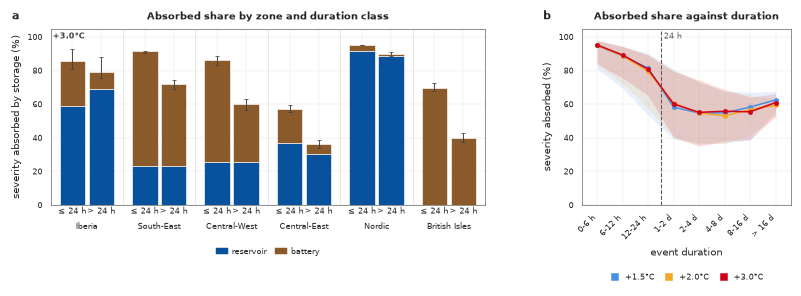

In [41]:
with publication_rc():
    save(figure5_variant("5A"), "set5A_fig5_panel_b", FIGS)
plt.show()

### Option 5B · absorbed share against event *size* rather than length

**What it adds.** Asks a different question: does storage struggle with *long* events or with
*big* ones? Binning on counterfactual severity rather than duration separates the two, and the
answer matters — a fixed store should be defeated by energy, not by clock time.

**Trade-off.** It breaks the shared x axis with Figure 2, so the two figures no longer line up, and
severity per event spans orders of magnitude so the axis has to be logarithmic. Duration is also the
variable the paper's classes are actually defined on, so this panel answers a question the rest of
the paper does not ask.


  set5B_fig5_panel_b           179.8 x  59.9 mm   panel 40.8 mm   pdf 41 kB  png 183 kB


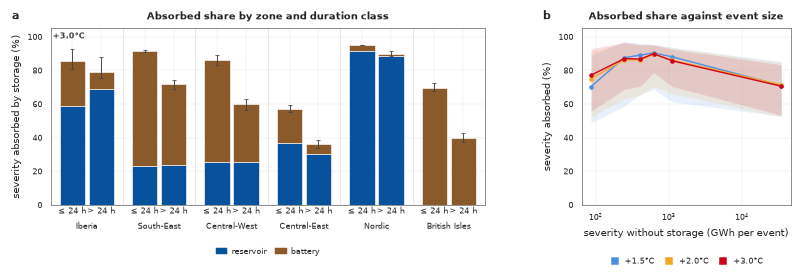

In [43]:
with publication_rc():
    save(figure5_variant("5B"), "set5B_fig5_panel_b", FIGS)
plt.show()

### Option 5C · absolute absorbed and unabsorbed energy, stacked

**What it adds.** The absolute picture the percentage hides. Panel a says Central-East absorbs
36 % of its multi-day severity; this says how many TWh that is, and where in the duration range the
unabsorbed remainder actually accumulates.

**Trade-off.** It is a level at one warming level only — stacking three warming levels would need
three times the bars — so the warming signal drops out of panel b entirely. It also changes panel
b's subject from *storage capability* to *energy accounting*, which is a different figure's job.


  set5C_fig5_panel_b           179.8 x  63.6 mm   panel 40.8 mm   pdf 46 kB  png 149 kB


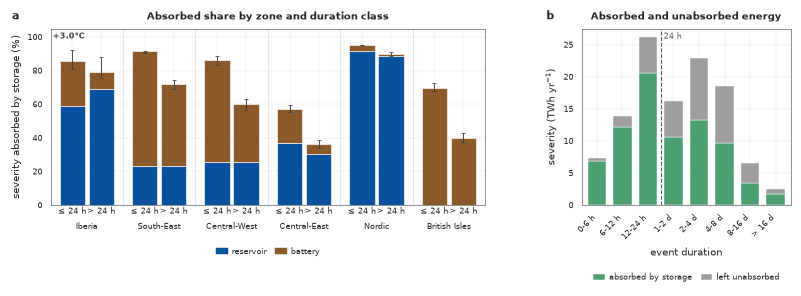

In [45]:
with publication_rc():
    save(figure5_variant("5C"), "set5C_fig5_panel_b", FIGS)
plt.show()

### Option 5D · event-count histogram by duration

**What it adds.** The distribution the 24 h split is drawn on, in the same panel as the
absorption result.

**Trade-off.** This is option 3B's panel a. If Figure 2 adopts 3C, this draws the same distribution
twice in one paper — and the second time without the severity counterpart that made it meaningful.
Choose this only if Figure 2 keeps its zonal burden panel.


  set5D_fig5_panel_b           179.9 x  63.6 mm   panel 40.8 mm   pdf 41 kB  png 187 kB


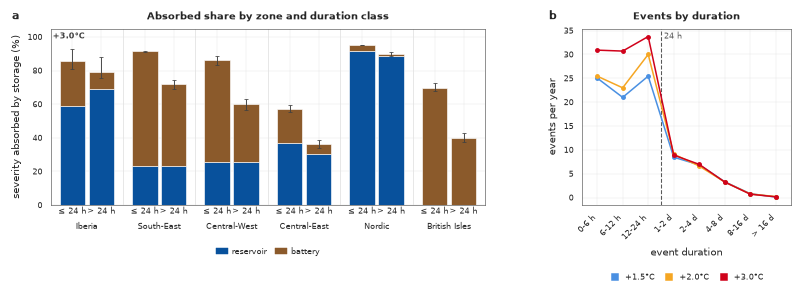

In [47]:
with publication_rc():
    save(figure5_variant("5D"), "set5D_fig5_panel_b", FIGS)
plt.show()

### Option 5E · counts over absorbed share, sharing one duration axis

**What it adds.** The two questions a reader has about the split, stacked and reading down a
column: how many events are in each bin, and what fraction storage takes out of them. No second
y-axis is involved — they are two panels sharing an x.

**Trade-off.** It costs vertical space that Figure 5 does not obviously have, it makes panel b twice
as tall as panel a beside it, and it carries the same duplication risk as 5D against option 3C.


  set5E_fig5_panel_b           179.9 x  77.5 mm   panel 54.7 mm   pdf 43 kB  png 233 kB


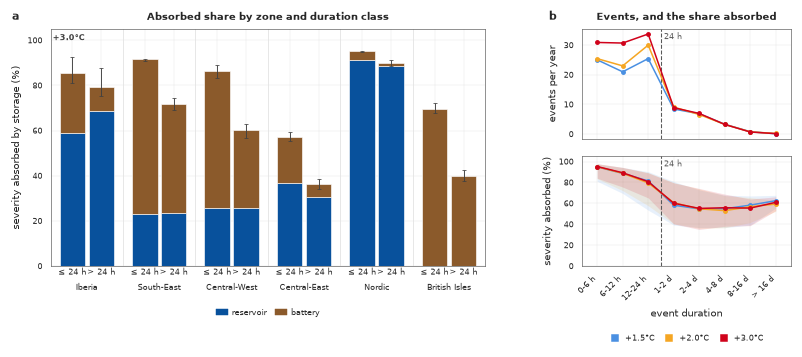

In [49]:
with publication_rc():
    save(figure5_variant("5E"), "set5E_fig5_panel_b", FIGS)
plt.show()

### Option 5F · absolute energy over absorbed share, sharing one duration axis

**What it adds.** The strongest self-contained version: where the energy is, and what share of
it storage removes, on one duration axis. It answers the review's "the absolute values tell
something different" without a dual axis and without depending on Figure 2.

**Trade-off.** The top sub-panel is a single-warming-level level while the bottom carries all three,
so the two halves are not on the same footing and the caption has to say which is which. It is also
the busiest of the six — four series and two scales in a 65 mm panel.


  set5F_fig5_panel_b           179.9 x  81.1 mm   panel 54.7 mm   pdf 50 kB  png 219 kB


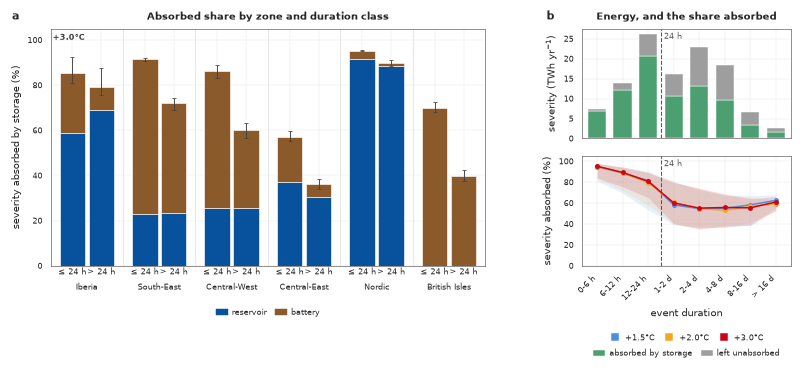

In [51]:
with publication_rc():
    save(figure5_variant("5F"), "set5F_fig5_panel_b", FIGS)
plt.show()